Loading dataset...
Training the Random Forest model...

 Model Training Complete!
Accuracy on test data: 97.60%

Detailed Report:
              precision    recall  f1-score   support

        Drag       0.95      0.99      0.97       343
  Left_Click       0.97      0.99      0.98       308
        Move       0.97      0.97      0.97       438
     Neutral       0.98      0.89      0.93       239
 Right_Click       0.99      0.99      0.99       325
      Scroll       0.99      1.00      0.99       349

    accuracy                           0.98      2002
   macro avg       0.98      0.97      0.97      2002
weighted avg       0.98      0.98      0.98      2002



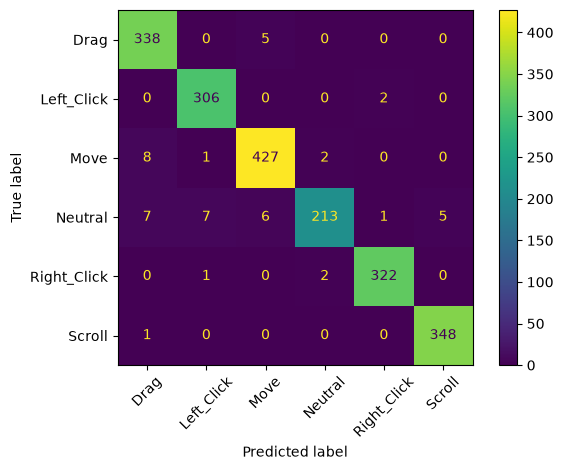

Brain saved successfully as 'd:\My Codes\Projects\AI\Virtual Mouse\Virtual Mouse\Model_Training\virtual_mouse_brain.pkl'


In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report,confusion_matrix,ConfusionMatrixDisplay
import pickle
import matplotlib.pyplot as plt

import sys
import os


current_dir = os.getcwd()
sys.path.append(os.path.abspath(os.path.join(current_dir, "../..")))

csv_path = os.path.abspath(
    os.path.join(
        current_dir, "..", "Data_Engineering", "Dataset", "virtual_mouse_data.csv"
    )
)

print("Loading dataset...")
df = pd.read_csv(csv_path)

X = df.drop("gesture_label", axis=1) #  axis delete column 
y = df["gesture_label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42 , stratify=y # spill all the moves to 0.2 as test_size
)

print("Training the Random Forest model...")
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"\n Model Training Complete!")
print(f"Accuracy on test data: {accuracy * 100:.2f}%\n")
print("Detailed Report:")
print(classification_report(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

model_filename = os.path.join(current_dir, "virtual_mouse_brain.pkl")
with open(model_filename, "wb") as f:
    pickle.dump(model, f)

print(f"Brain saved successfully as '{model_filename}'")
